# 01 - Validation and EDA
**All data is synthetic.** Every number in this notebook is "on synthetic data".
Source of truth: `docs/assumptions.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

from src.config import DATA_RAW, FIGURES, ensure_dirs, set_seed
from src.validate import validate_frame

set_seed()
ensure_dirs()
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#2a78d6", "#eb6834"
CLASSES = ["no_risk", "low", "moderate", "crisis"]

df = pd.read_csv(DATA_RAW / "conversations.csv")
print(validate_frame(df))
df["period"] = np.where(df.week <= 16, "weeks 1-16", "weeks 17-26")
df["n_words"] = df.text.str.split().str.len()
df.head(3)

{'rows': 6000, 'weeks': '1-26', 'families': 399, 'label_noise_rate': 0.025, 'status': 'PASS'}


,conversation_id,week,channel,language,age_band,text,risk_level,escalate_needed,label_delay_weeks,template_family,risk_level_clean,gen_asr_wer,period,n_words
0,C00001,1,text,en,35-49,My doctor suggested I reach out. It's probably...,no_risk,0,1,B-no_risk-136,no_risk,NaN,weeks 1-16,33
1,C00002,1,voice,en,35-49,my neighbor last sear and i'm helping with fam...,no_risk,0,4,B-no_risk-062,no_risk,0.117106,weeks 1-16,35
2,C00003,1,text,en,35-49,I need a refill of my prescription before the ...,no_risk,0,4,B-no_risk-024,no_risk,NaN,weeks 1-16,34


## 1. Class balance

,n,pct
risk_level,,
no_risk,4111,68.52
low,1104,18.40
moderate,537,8.95
crisis,248,4.13


class mix (%) by period:


risk_level,no_risk,low,moderate,crisis
period,,,,
weeks 1-16,67.75,18.75,9.17,4.33
weeks 17-26,69.75,17.84,8.59,3.82


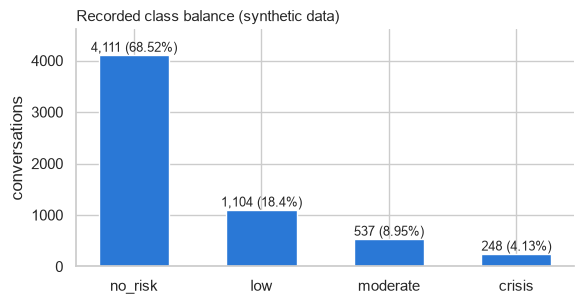

In [2]:
bal = (df.risk_level.value_counts().reindex(CLASSES).to_frame("n")
       .assign(pct=lambda d: (100 * d.n / d.n.sum()).round(2)))
display(bal)
by_period = pd.crosstab(df.period, df.risk_level, normalize="index").reindex(columns=CLASSES).mul(100).round(2)
print("class mix (%) by period:")
display(by_period)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(bal.index, bal.n, color=BLUE, width=0.55)
for i, (n, p) in enumerate(zip(bal.n, bal.pct)):
    ax.text(i, n + 60, f"{n:,} ({p}%)", ha="center", fontsize=9)
ax.set_ylabel("conversations")
ax.set_title("Recorded class balance (synthetic data)", loc="left", fontsize=11)
ax.set_ylim(0, bal.n.max() * 1.12)
fig.tight_layout()
fig.savefig(FIGURES / "eda_class_balance.png", dpi=150)
plt.show()

## 2. Text length by class and channel

,count,mean,std,min,25%,50%,75%,max
risk_level,,,,,,,,
no_risk,4111.0,25.4,7.4,7.0,20.0,25.0,30.0,53.0
low,1104.0,25.2,6.5,9.0,21.0,25.0,29.0,48.0
moderate,537.0,25.4,6.4,10.0,21.0,25.0,29.0,45.0
crisis,248.0,27.3,5.8,14.0,23.0,27.0,31.2,42.0


risk_level,no_risk,low,moderate,crisis
channel,,,,
text,25.3,25.0,25.6,27.8
voice,25.7,25.4,25.0,26.7


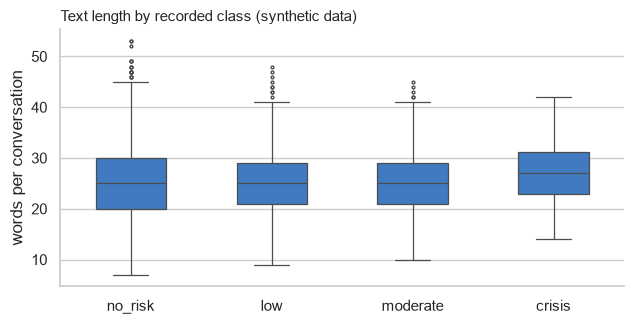

In [3]:
display(df.groupby("risk_level").n_words.describe().reindex(CLASSES).round(1))
display(df.groupby(["channel", "risk_level"]).n_words.mean().unstack().reindex(columns=CLASSES).round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
sns.boxplot(data=df, x="risk_level", y="n_words", order=CLASSES, color=BLUE,
            fliersize=2, linewidth=0.9, width=0.5, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("words per conversation")
ax.set_title("Text length by recorded class (synthetic data)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "eda_text_length.png", dpi=150)
plt.show()

## 3. Channel, language and age mix, and how they shift at week 17

,voice share,spanish-mixed share,mean ASR WER (voice),mean words
period,,,,
weeks 1-16,0.350,0.099,0.099,25.686
weeks 17-26,0.546,0.095,0.161,25.108


crisis rate (%) by channel / language, recorded labels:


,crisis %
channel,
text,4.15
voice,4.12


,mean,sum,count
language,,,
en,0.0418,226,5413
en_es,0.0375,22,587


age band mix (%):


age_band
18-24    17.4
25-34    26.3
35-49    27.4
50-64    18.3
65+      10.6
Name: proportion, dtype: float64

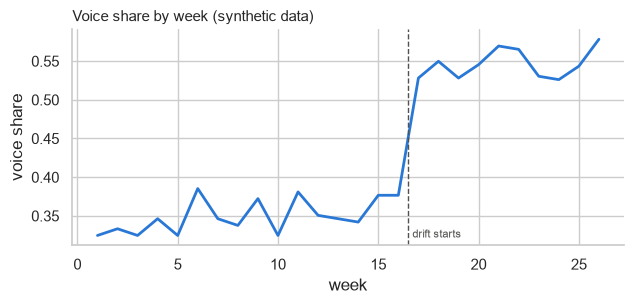

In [4]:
mix = pd.DataFrame({
    "voice share": df.groupby("period").channel.apply(lambda s: (s == "voice").mean()),
    "spanish-mixed share": df.groupby("period").language.apply(lambda s: (s == "en_es").mean()),
    "mean ASR WER (voice)": df.groupby("period").gen_asr_wer.mean(),
    "mean words": df.groupby("period").n_words.mean(),
}).round(3)
display(mix)
print("crisis rate (%) by channel / language, recorded labels:")
display((df.assign(is_crisis=df.risk_level.eq("crisis"))
         .groupby("channel").is_crisis.mean().mul(100).round(2).to_frame("crisis %")))
display((df.assign(is_crisis=df.risk_level.eq("crisis"))
         .groupby("language").is_crisis.agg(["mean", "sum", "count"]).round(4)))
print("age band mix (%):")
display(df.age_band.value_counts(normalize=True).sort_index().mul(100).round(1))

voice_by_week = df.groupby("week").channel.apply(lambda s: (s == "voice").mean())
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(voice_by_week.index, voice_by_week.values, color=BLUE, lw=2)
ax.axvline(16.5, color="#52514e", lw=1, ls="--")
ax.text(16.7, ax.get_ylim()[0] + 0.01, "drift starts", fontsize=8, color="#52514e")
ax.set_xlabel("week")
ax.set_ylabel("voice share")
ax.set_title("Voice share by week (synthetic data)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "eda_voice_share_by_week.png", dpi=150)
plt.show()

## 4. Duplicates and near-duplicates

In [5]:
exact = int(df.text.duplicated(keep=False).sum())
print(f"rows whose exact text appears more than once: {exact} ({100 * exact / len(df):.1f}%)")

vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1)
X = vec.fit_transform(df.text)
fam = df.template_family.to_numpy()
nn_sim = np.zeros(len(df))
nn_same_family = np.zeros(len(df), dtype=bool)
for start in range(0, len(df), 500):
    stop = min(start + 500, len(df))
    sims = (X[start:stop] @ X.T).toarray()
    sims[np.arange(stop - start), np.arange(start, stop)] = -1  # exclude self
    j = sims.argmax(axis=1)
    nn_sim[start:stop] = sims[np.arange(stop - start), j]
    nn_same_family[start:stop] = fam[start:stop] == fam[j]
df["nn_sim"], df["nn_same_family"] = nn_sim, nn_same_family

for thr in (0.6, 0.7, 0.8, 0.9):
    hit = df.nn_sim >= thr
    print(f"nearest-neighbour cosine >= {thr}: {100 * hit.mean():5.1f}% of rows | "
          f"of those, nearest neighbour is in the SAME family: {100 * df.nn_same_family[hit].mean():5.1f}%")

rows whose exact text appears more than once: 44 (0.7%)


nearest-neighbour cosine >= 0.6:  46.3% of rows | of those, nearest neighbour is in the SAME family:  55.7%
nearest-neighbour cosine >= 0.7:  22.0% of rows | of those, nearest neighbour is in the SAME family:  62.5%
nearest-neighbour cosine >= 0.8:   7.5% of rows | of those, nearest neighbour is in the SAME family:  67.6%
nearest-neighbour cosine >= 0.9:   1.6% of rows | of those, nearest neighbour is in the SAME family:  80.0%


## 5. Label-noise audit
In real data we would not know the clean label. Here we do, so we can measure the
noise exactly, and also practise the manual audit on a random sample.

In [6]:
print(pd.crosstab(df.risk_level_clean, df.risk_level).reindex(index=CLASSES, columns=CLASSES))
noisy = df[df.risk_level != df.risk_level_clean]
print(f"\nrecorded label differs from clean label: {len(noisy)} rows ({100 * len(noisy) / len(df):.2f}%)")
print("noisy rows by recorded class:", noisy.risk_level.value_counts().to_dict())

pd.set_option("display.max_colwidth", 200)
audit = df.sample(40, random_state=42)[["conversation_id", "channel", "risk_level", "text"]]
print("\nManual audit sample: read each row, ask 'would I assign the recorded label?'")
display(audit.head(15))

risk_level        no_risk  low  moderate  crisis
risk_level_clean                                
no_risk              4100  100         0       0
low                    11  996        13       0
moderate                0    8       519      13
crisis                  0    0         5     235

recorded label differs from clean label: 150 rows (2.50%)
noisy rows by recorded class: {'low': 108, 'moderate': 18, 'crisis': 13, 'no_risk': 11}

Manual audit sample: read each row, ask 'would I assign the recorded label?'


,conversation_id,channel,risk_level,text
1782,C01783,text,no_risk,"So, um, yeah. I never got the intake forms yet. Please let me know what the next step is."
3917,C03918,text,low,I lost my appetite a bit but I'm coping. The weather has been awful lately. Sorry if this is a lot.
221,C00222,text,no_risk,"So, um, yeah. Tbh in the show I watched the father dies and my class wants to discsus it, unrelated, can you help me with a refill."
2135,C02136,voice,no_risk,hey ngl la verdad my job is going to be the death of me now anyway i so just uh need to confirm my visit thanks so
5224,C05225,voice,no_risk,my doctor suggested i reach out i am calling to change my you know emergency i tried a counselor once but it didn't stick is you a nurse i can speak to
1168,C01169,text,no_risk,"It's prrobably nothing but can you tell me whether you take my insurance. Hello, thanks for picking up. My kdis are at their dad's this week. That's all."
879,C00880,text,no_risk,"Hello, thanks for picking up. In the show we saw the father dies and my friend wants to talk about it, unrelated, can you help me with a refill. I don't know what to do."
156,C00157,text,no_risk,Hey. I am calling to change my insurance dettails. I don't know what to do.
1657,C01658,text,low,"Good morning. La verdad, my boss is killing me, I could use some coping tips. I've been busy with work. Sorry if this is a lot."
323,C00324,voice,no_risk,hey nunca pienso en hacerme daño necesito with formularios my insurance changed recently can someone help me


## 6. Findings (all on synthetic data)

1. **Accuracy is a trap.** Only 248 of 6,000 conversations (4.1%) carry a recorded
   crisis label, and 68.5% are no_risk. A model that always says "no_risk" scores
   68.5% accuracy and catches zero crises, so we judge models on crisis-class recall,
   precision and PR-AUC. Prevalence is stable over time (4.3% in weeks 1-16, 3.8% in
   weeks 17-26), so the drift scenario is an input shift, not a base-rate shift.
2. **Text length is not a shortcut.** The median is 25 words in every class. Crisis
   texts are about 2 words longer on average (27.3 vs 25.2-25.4), a weak cue at best.
3. **The drift is built in as intended, and voice is not "riskier".** Voice share
   rises from 35.0% to 54.6% and mean ASR word error rate from 9.9% to 16.1% at week 17,
   while the Spanish-mixed share stays flat (9.9% vs 9.5%). The crisis rate is the same
   in both channels (4.15% text vs 4.12% voice), so any later voice gap comes from
   noise, not from base rate.
4. **Near-duplicates are common, so a random split would leak.** 0.7% of rows are exact
   duplicates, 22% of rows have a near-twin at TF-IDF cosine >= 0.7, and 7.5% at >= 0.8.
   Of the pairs at >= 0.8, 68% sit in the same template family, which is the leakage a
   group split removes. The other 32% are across families (shared core phrasing),
   which a family split cannot remove. This is a known limitation, recorded in
   docs/assumptions.md.
5. **Label noise caps what any model can score.** 150 rows (2.5%) have a recorded label
   that differs from the clean label. 100 of the 4,200 true no_risk rows were recorded as
   low, so about 9% of recorded "low" is really no_risk. Within crisis, 13 of 248 recorded
   crisis rows are really moderate, and 5 true crisis rows were recorded as moderate. An
   oracle that knew the clean labels would score crisis recall 235/248 = 0.948 and
   precision 235/240 = 0.979 against the recorded labels. The pre-registered recall
   target of 0.95 is therefore just above the oracle's recall, and can only be reached by
   also flagging some moderate-looking cases at a precision cost. We will report this
   openly. Also note that only 22 recorded crisis rows are Spanish-mixed, so Spanish slice
   recall will have a very wide confidence interval.